# Mapping the uninfected macaque lung atlas to the Human Lung Cell Atlas (HLCA)

In [1]:
import os
import warnings

warnings.simplefilter(action="ignore", category=FutureWarning)
warnings.simplefilter(action="ignore", category=DeprecationWarning)
warnings.simplefilter(action="ignore", category=UserWarning)

In [2]:
import sys
import scanpy as sc
import numpy as np
import pandas as pd
import scarches as sca
import anndata as ad
from scipy import sparse
import shutil
import urllib.request

import scvi
import torch
from scvi.hub import HubModel

 captum (see https://github.com/pytorch/captum).


In [3]:
print("python:", sys.executable)
for name, mod in [("scanpy", sc), ("numpy", np), ("pandas", pd), ("anndata", ad),
                  ("scvi-tools", scvi), ("scarches", sca), ("torch", torch)]:
    print(f"{name:12s}", mod.__version__)
print("CUDA available:", torch.cuda.is_available())

scvi.settings.seed = 42

INFO: [rank: 0] Seed set to 42
INFO:lightning.fabric.utilities.seed:[rank: 0] Seed set to 42


python: /gpfs/projects/kawaldorflab/software/miniconda3/envs/scArches/bin/python
scanpy       1.11.5
numpy        2.2.6
pandas       2.3.3
anndata      0.11.4
scvi-tools   1.3.3
scarches     0.6.1
torch        2.9.1+cu128
CUDA available: True


In [4]:
sc.settings.set_figure_params(dpi=200, frameon=False)
sc.set_figure_params(dpi=200)
sc.set_figure_params(figsize=(4, 4))

In [5]:
base_dir = "/gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas"
hlca_dir = os.path.join(base_dir, "HLCA")

# inputs
path_query_source = os.path.join(base_dir, "output", "scanvi_output_v2.h5ad")
path_final_cells = os.path.join(hlca_dir, "final_cells_for_hlca.csv") 
path_orthologs = os.path.join(hlca_dir, "mmul113_to_human_orthologs.csv") 
hub_cache_dir = os.path.join(hlca_dir, "hub_cache")
hub_repo = "scvi-tools/human-lung-cell-atlas-scanvi"
hub_revision = "6978d287b08ac777ca7c015e5220f2feec29ad0a"

# outputs
surgery_model_dir = os.path.join(hlca_dir, "surgery_model")
path_celltypes = os.path.join(hlca_dir, "HLCA_celltypes_ordered.csv")
path_combined_emb = os.path.join(hlca_dir, "combined_embedding.h5ad")
path_query_final = os.path.join(hlca_dir, "query_with_refbased_emb_and_anns.h5ad")
path_labels_csv = os.path.join(hlca_dir, "hlca_label_transfer.csv")
path_summary_csv = os.path.join(hlca_dir, "hlca_label_transfer_summary.csv")

In [6]:
hub = HubModel.pull_from_huggingface_hub(
    repo_name=hub_repo,
    cache_dir=hub_cache_dir,
    revision=hub_revision,
)
ref_model_dir = hub.local_dir
print(ref_model_dir)
print(hub.metadata)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

/gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/HLCA/hub_cache/models--scvi-tools--human-lung-cell-atlas-scanvi/snapshots/6978d287b08ac777ca7c015e5220f2feec29ad0a
HubMetadata(scvi_version='1.4.2', anndata_version='0.12.7', model_cls_name='SCANVI', training_data_url=None, model_parent_module='scvi.model')


In [7]:
hub_adata = hub.adata
print(hub_adata)
adata_ref = sc.AnnData(X=np.asarray(hub_adata.obsm["X_scanvi_emb"], dtype=np.float32), obs=hub_adata.obs.copy())
adata_ref

INFO     Reading adata...                                                                                          
INFO     No data found on disk. Skipping...                                                                        
AnnData object with n_obs × n_vars = 584944 × 2000
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'sex_ontology_term_id', 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'dataset', 'entropy_dataset_leiden_3', 'entropy_original_ann_level_1_leiden_3', 'entropy_original_ann_level_2_clean_leiden_3', 'entropy_original_ann_level_3_clean_leiden_3', 'entropy_subject_ID_leiden_3', 'fresh_o

AnnData object with n_obs × n_vars = 584944 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'sex_ontology_term_id', 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'dataset', 'entropy_dataset_leiden_3', 'entropy_original_ann_level_1_leiden_3', 'entropy_original_ann_level_2_clean_leiden_3', 'entropy_original_ann_level_3_clean_leiden_3', 'entropy_subject_ID_leiden_3', 'fresh_or_frozen', 'leiden_1', 'leiden_2', 'leiden_3', 'leiden_4', 'leiden_5', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'n_genes_detected', 'original_ann_highest_res', 'original_ann_level_1', 'original_ann_level_2', 'original

In [8]:
cols_to_drop = [
    col for col in adata_ref.obs.columns if adata_ref.obs[col].isnull().all()
]
adata_ref.obs.drop(columns=cols_to_drop, inplace=True)

In [9]:
rng = np.random.default_rng(0)
idx = rng.choice(hub_adata.n_obs, size=20000, replace=False)
emb_pub = np.asarray(hub_adata.obsm["X_scanvi_emb"][idx], dtype=np.float64)
emb_model = np.asarray(hub_adata.obsm["scanvi_latent_qzm"][idx], dtype=np.float64)
r = np.corrcoef(emb_pub.ravel(), emb_model.ravel())[0, 1]
print(f"correlation = {r:.5f} | max abs difference = {np.abs(emb_pub - emb_model).max():.5f}")
assert r > 0.99, "Published embedding and model latent differ: use obsm['scanvi_latent_qzm'] for adata_ref."

correlation = 0.99854 | max abs difference = 0.54979


In [10]:
adata_src = sc.read_h5ad(path_query_source)
final_cells = pd.read_csv(path_final_cells)

missing = set(final_cells["cell"]) - set(adata_src.obs_names)
assert len(missing) == 0, f"{len(missing)} final cells not found in the h5ad"

adata_src = adata_src[final_cells["cell"].values].copy()
assert (adata_src.obs_names == final_cells["cell"].values).all()
adata_src.X = adata_src.layers["counts"].copy()
adata_src

AnnData object with n_obs × n_vars = 61612 × 21591
    obs: 'sample', 'batch', 'gem_group', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'leiden', 'leiden_initial', 'scanvi_predictions', 'scanvi_prediction_score'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'hvg', 'log1p'
    obsm: 'X_scanvi', 'X_scvi', 'X_umap'
    layers: 'counts'

In [11]:
orth = pd.read_csv(path_orthologs)
o2o = orth.loc[
    orth["Human homology type"] == "ortholog_one2one",
    ["Gene stable ID", "Human gene stable ID"],
].drop_duplicates()
assert o2o["Gene stable ID"].is_unique and o2o["Human gene stable ID"].is_unique
mmul_to_human = dict(zip(o2o["Gene stable ID"], o2o["Human gene stable ID"]))

keep = adata_src.var["gene_ids"].isin(mmul_to_human).values
adata_query_unprep = ad.AnnData(
    X=adata_src.X[:, keep],
    obs=pd.DataFrame(
        {"sample": adata_src.obs["sample"].astype(str).values,
         "cell_type_v2": final_cells["cell_type_v2"].values},
        index=adata_src.obs_names,
    ),
    var=pd.DataFrame(
        {"gene_ids_mmul": adata_src.var["gene_ids"].values[keep],
         "gene_names": adata_src.var_names[keep].values},
        index=[mmul_to_human[g] for g in adata_src.var["gene_ids"].values[keep]],
    ),
)

adata_query_unprep.var.index.name = None
adata_query_unprep.var["gene_ids"] = adata_query_unprep.var.index
assert adata_query_unprep.var_names.is_unique
del adata_src
adata_query_unprep

AnnData object with n_obs × n_vars = 61612 × 16465
    obs: 'sample', 'cell_type_v2'
    var: 'gene_ids_mmul', 'gene_names', 'gene_ids'

In [12]:
adata_query_unprep.X = sparse.csr_matrix(adata_query_unprep.X)

In [13]:
del adata_query_unprep.obsm
del adata_query_unprep.varm

In [14]:
adata_query_unprep.X[:10, :30].toarray()

array([[0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 1],
       [2, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0],
       [2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 1, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 1],
       [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 1],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 2],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0],
       [0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0],
       [0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [15]:
assert np.all(np.mod(adata_query_unprep.X.data, 1) == 0), "adata.X is not raw integer counts"

In [16]:
ref_model_features = sca.models.SCANVI.prepare_query_anndata(
    adata=adata_query_unprep, reference_model=ref_model_dir, return_reference_var_names=True
)
ref_model_features[:5]

INFO     File                                                                                                      
         /gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/HLCA/hub_cache/models--scvi-tools--human-lung-ce
         ll-atlas-scanvi/snapshots/6978d287b08ac777ca7c015e5220f2feec29ad0a/model.pt already downloaded            


Index(['ENSG00000000938', 'ENSG00000000971', 'ENSG00000002587',
       'ENSG00000002933', 'ENSG00000003436'],
      dtype='object')

In [17]:
n_overlap = adata_query_unprep.var_names.isin(ref_model_features).sum()
n_genes_model = len(ref_model_features)
print(
    f"Number of model input genes detected: {n_overlap} out of {n_genes_model} ({round(n_overlap/n_genes_model*100)}%)"
)

Number of model input genes detected: 1612 out of 2000 (81%)


In [18]:
adata_query = sca.models.SCANVI.prepare_query_anndata(
    adata=adata_query_unprep, reference_model=ref_model_dir, inplace=False
)

INFO     File                                                                                                      
         /gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/HLCA/hub_cache/models--scvi-tools--human-lung-ce
         ll-atlas-scanvi/snapshots/6978d287b08ac777ca7c015e5220f2feec29ad0a/model.pt already downloaded            
INFO     Found 80.60000000000001% reference vars in query data.                                                    


In [19]:
adata_query

AnnData object with n_obs × n_vars = 61612 × 2000
    obs: 'sample', 'cell_type_v2'
    var: 'gene_ids_mmul', 'gene_names', 'gene_ids'

In [20]:
ref_model = hub.model
ref_model.registry_["setup_args"]

INFO     Loading model...                                                                                          
INFO     File                                                                                                      
         /gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/HLCA/hub_cache/models--scvi-tools--human-lung-ce
         ll-atlas-scanvi/snapshots/6978d287b08ac777ca7c015e5220f2feec29ad0a/model.pt already downloaded            


{'labels_key': 'scanvi_label',
 'unlabeled_category': 'unlabeled',
 'layer': None,
 'batch_key': 'dataset',
 'size_factor_key': None,
 'categorical_covariate_keys': None,
 'continuous_covariate_keys': None,
 'use_minified': True}

In [21]:
adata_query.obs["dataset"] = "KAWLab_macaque_lung"

In [22]:
adata_query.obs["scanvi_label"] = "unlabeled"

In [24]:
surgery_model = sca.models.SCANVI.load_query_data(
    adata_query,
    ref_model,
    freeze_dropout=True,
)
surgery_model.registry_["setup_args"]

{'labels_key': 'scanvi_label',
 'unlabeled_category': 'unlabeled',
 'layer': None,
 'batch_key': 'dataset',
 'size_factor_key': None,
 'categorical_covariate_keys': None,
 'continuous_covariate_keys': None,
 'use_minified': True}

In [25]:
surgery_epochs = 500
early_stopping_kwargs_surgery = {
    "early_stopping": True, 
    "early_stopping_monitor": "elbo_train",
    "early_stopping_patience": 10,
    "early_stopping_min_delta": 0.001,
    "plan_kwargs": {"weight_decay": 0.0},
}

In [26]:
surgery_model.train(max_epochs=surgery_epochs, **early_stopping_kwargs_surgery)

INFO     Training for 500 epochs.                                                                                  


INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: You are using a CUDA device ('NVIDIA H200') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
INFO:lightning.pytorch.utilities.rank_zero:You are using a CUDA device ('NVIDIA H200') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul

Training:   0%|          | 0/500 [00:00<?, ?it/s]

Monitored metric elbo_train did not improve in the last 10 records. Best score: 845.956. Signaling Trainer to stop.


In [27]:
print("epochs trained:", len(surgery_model.history["elbo_train"]))

epochs trained: 344


In [28]:
surgery_model.save(surgery_model_dir, overwrite=True)

In [29]:
surgery_model = sca.models.SCANVI.load(
    surgery_model_dir, adata_query
)

INFO     File /gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/HLCA/surgery_model/model.pt already        
         downloaded                                                                                                


In [30]:
adata_query_latent = sc.AnnData(surgery_model.get_latent_representation(adata_query))

In [31]:
adata_query_latent.obs = adata_query.obs.loc[adata_query.obs.index, :]

In [32]:
adata_query_latent.obs["ref_or_query"] = "query"
adata_ref.obs["ref_or_query"] = "ref"

In [33]:
combined_emb = sc.concat(
    (adata_ref, adata_query_latent), index_unique=None, join="outer"
)
assert combined_emb.obs_names.is_unique

In [34]:
for cat in combined_emb.obs.columns:
    if isinstance(combined_emb.obs[cat].values, pd.Categorical):
        pass
    elif pd.api.types.is_float_dtype(combined_emb.obs[cat]):
        pass
    else:
        print(
            f"Setting obs column {cat} (not categorical neither float) to strings to prevent writing error."
        )
        combined_emb.obs[cat] = combined_emb.obs[cat].astype(str)

Setting obs column is_primary_data (not categorical neither float) to strings to prevent writing error.
Setting obs column dataset (not categorical neither float) to strings to prevent writing error.
Setting obs column sample (not categorical neither float) to strings to prevent writing error.
Setting obs column scanvi_label (not categorical neither float) to strings to prevent writing error.
Setting obs column observation_joinid (not categorical neither float) to strings to prevent writing error.
Setting obs column _scvi_batch (not categorical neither float) to strings to prevent writing error.
Setting obs column _scvi_labels (not categorical neither float) to strings to prevent writing error.
Setting obs column ref_or_query (not categorical neither float) to strings to prevent writing error.
Setting obs column cell_type_v2 (not categorical neither float) to strings to prevent writing error.


In [35]:
combined_emb.write_h5ad(path_combined_emb)

In [36]:
combined_emb = sc.read_h5ad(path_combined_emb)

In [37]:
url = "https://github.com/LungCellAtlas/HLCA_reproducibility/raw/main/supporting_files/celltype_structure_and_colors/manual_anns_and_leveled_anns_ordered.csv"
urllib.request.urlretrieve(url, path_celltypes)

('/gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/HLCA/HLCA_celltypes_ordered.csv',
 <http.client.HTTPMessage at 0x14c31f7bb9a0>)

In [38]:
cts_ordered = pd.read_csv(path_celltypes, index_col=0).rename(
    columns={f"Level_{lev}": f"labtransf_ann_level_{lev}" for lev in range(1, 6)}
)

In [39]:
cts_ordered.head(5)

,labtransf_ann_level_1,labtransf_ann_level_2,labtransf_ann_level_3,labtransf_ann_level_4,labtransf_ann_level_5,ordering,colors
Basal resting,Epithelial,Airway epithelium,Basal,Basal resting,4_Basal resting,3,#FFFF00
Suprabasal,Epithelial,Airway epithelium,Basal,Suprabasal,4_Suprabasal,4,#1CE6FF
Hillock-like,Epithelial,Airway epithelium,Basal,Hillock-like,4_Hillock-like,11,#FF34FF
Deuterosomal,Epithelial,Airway epithelium,Multiciliated lineage,Deuterosomal,4_Deuterosomal,13,#FF4A46
Multiciliated (nasal),Epithelial,Airway epithelium,Multiciliated lineage,Multiciliated,Multiciliated (nasal),15,#008941


In [40]:
missing_cts = set(adata_ref.obs["ann_finest_level"].astype(str)) - set(cts_ordered.index)
assert len(missing_cts) == 0, f"finest labels missing from the table: {missing_cts}"

In [41]:
adata_ref.obs = adata_ref.obs.join(cts_ordered, on="ann_finest_level")

In [42]:
adata_ref

AnnData object with n_obs × n_vars = 584944 × 30
    obs: 'suspension_type', 'donor_id', 'is_primary_data', 'assay_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'disease_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'tissue_ontology_term_id', 'sex_ontology_term_id', 'BMI', 'age_or_mean_of_age_range', 'age_range', 'anatomical_region_ccf_score', 'ann_coarse_for_GWAS_and_modeling', 'ann_finest_level', 'ann_level_1', 'ann_level_2', 'ann_level_3', 'ann_level_4', 'ann_level_5', 'cause_of_death', 'dataset', 'entropy_dataset_leiden_3', 'entropy_original_ann_level_1_leiden_3', 'entropy_original_ann_level_2_clean_leiden_3', 'entropy_original_ann_level_3_clean_leiden_3', 'entropy_subject_ID_leiden_3', 'fresh_or_frozen', 'leiden_1', 'leiden_2', 'leiden_3', 'leiden_4', 'leiden_5', 'log10_total_counts', 'lung_condition', 'mixed_ancestry', 'n_genes_detected', 'original_ann_highest_res', 'original_ann_level_1', 'original_ann_level_2', 'original

In [43]:
adata_ref.obs.loc[:, ["ann_finest_level", "labtransf_ann_level_4"]].head(5)

,ann_finest_level,labtransf_ann_level_4
GCGACCATCCCTAACC_SC22,Alveolar macrophages,Alveolar macrophages
P2_1_GCGCAACCAGTTAACC,NK cells,NK cells
GCTCTGTAGTGCTGCC_SC27,AT2,3_AT2
P2_8_TTAGGACGTTCAGGCC,Alveolar Mph CCL3+,Alveolar macrophages
CTTGATTGTCAGTTTG_T164,Suprabasal,Suprabasal


In [44]:
knn_transformer = sca.utils.knn.weighted_knn_trainer(
    train_adata=adata_ref,
    train_adata_emb="X",
    n_neighbors=50,
)

Weighted KNN with n_neighbors = 50 ... 

In [45]:
labels, uncert = sca.utils.knn.weighted_knn_transfer(
    query_adata=adata_query_latent,
    query_adata_emb="X",
    label_keys="labtransf_ann_level_",
    knn_model=knn_transformer,
    ref_adata_obs=adata_ref.obs,
)

finished!


In [46]:
dist, ind = knn_transformer.kneighbors(X=adata_query_latent.X)
stds = (2.0 / np.std(dist, axis=1)) ** 2
w = np.exp(-dist / stds.reshape(-1, 1))
w = w / w.sum(axis=1, keepdims=True)
rows = np.repeat(np.arange(ind.shape[0]), ind.shape[1])

labels_check = pd.DataFrame(index=adata_query_latent.obs_names)
uncert_check = pd.DataFrame(index=adata_query_latent.obs_names)
for col in labels.columns:
    cats, codes = np.unique(adata_ref.obs[col].astype(str).values, return_inverse=True)
    P = np.zeros((ind.shape[0], len(cats)))
    np.add.at(P, (rows, codes[ind].ravel()), w.ravel())
    labels_check[col] = cats[P.argmax(axis=1)]
    uncert_check[col] = np.maximum(1 - P.max(axis=1), 0)

scarches_empty = labels.isna().all().all()
print("pandas version:", pd.__version__, "| scArches output empty:", scarches_empty)
if not scarches_empty:
    for col in labels.columns:
        agree = (labels[col].astype(str).values == labels_check[col].values).mean()
        diff = np.abs(uncert[col].astype(float).values - uncert_check[col].values).max()
        print(f"{col}: label agreement {agree:.6f} | max uncertainty difference {diff:.2e}")
else:
    print("scArches returned empty results (pandas >= 3). Using the independent implementation.")
    labels, uncert = labels_check.copy(), uncert_check.copy()

assert labels.notna().all().all()
uncert = uncert.astype(float)

pandas version: 2.3.3 | scArches output empty: False
labtransf_ann_level_1: label agreement 1.000000 | max uncertainty difference 7.77e-16
labtransf_ann_level_2: label agreement 1.000000 | max uncertainty difference 7.77e-16
labtransf_ann_level_3: label agreement 1.000000 | max uncertainty difference 7.77e-16
labtransf_ann_level_4: label agreement 1.000000 | max uncertainty difference 7.77e-16
labtransf_ann_level_5: label agreement 1.000000 | max uncertainty difference 7.77e-16


In [47]:
uncertainty_threshold = 0.2

In [48]:
labels.rename(
    columns={
        f"labtransf_ann_level_{lev}": f"ann_level_{lev}_transferred_label_unfiltered"
        for lev in range(1, 6)
    },
    inplace=True,
)
uncert.rename(
    columns={
        f"labtransf_ann_level_{lev}": f"ann_level_{lev}_transfer_uncert"
        for lev in range(1, 6)
    },
    inplace=True,
)

In [49]:
combined_emb.obs = combined_emb.obs.join(labels)
combined_emb.obs = combined_emb.obs.join(uncert)

In [50]:
for lev in range(1, 6):
    combined_emb.obs[f"ann_level_{lev}_transferred_label"] = combined_emb.obs[
        f"ann_level_{lev}_transferred_label_unfiltered"
    ].mask(
        combined_emb.obs[f"ann_level_{lev}_transfer_uncert"] > uncertainty_threshold,
        "Unknown",
    )

In [51]:
print(
    f"Percentage of unknown per level, with uncertainty_threshold={uncertainty_threshold}:"
)
for level in range(1, 6):
    print(
        f"Level {level}: {np.round(sum(combined_emb.obs[f'ann_level_{level}_transferred_label'] =='Unknown')/adata_query.n_obs*100,2)}%"
    )

Percentage of unknown per level, with uncertainty_threshold=0.2:
Level 1: 1.21%
Level 2: 2.57%
Level 3: 11.45%
Level 4: 31.83%
Level 5: 32.46%


In [52]:
sc.pp.neighbors(combined_emb, n_neighbors=30)
sc.tl.umap(combined_emb)

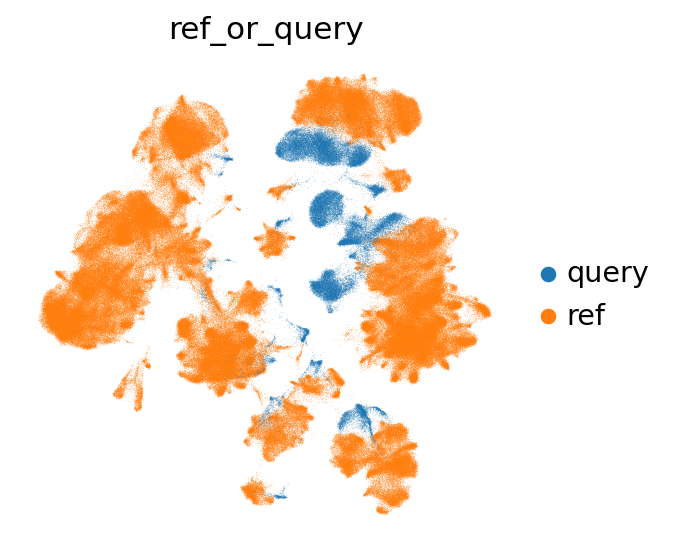

In [53]:
sc.pl.umap(combined_emb, color="ref_or_query", frameon=False, wspace=0.6)

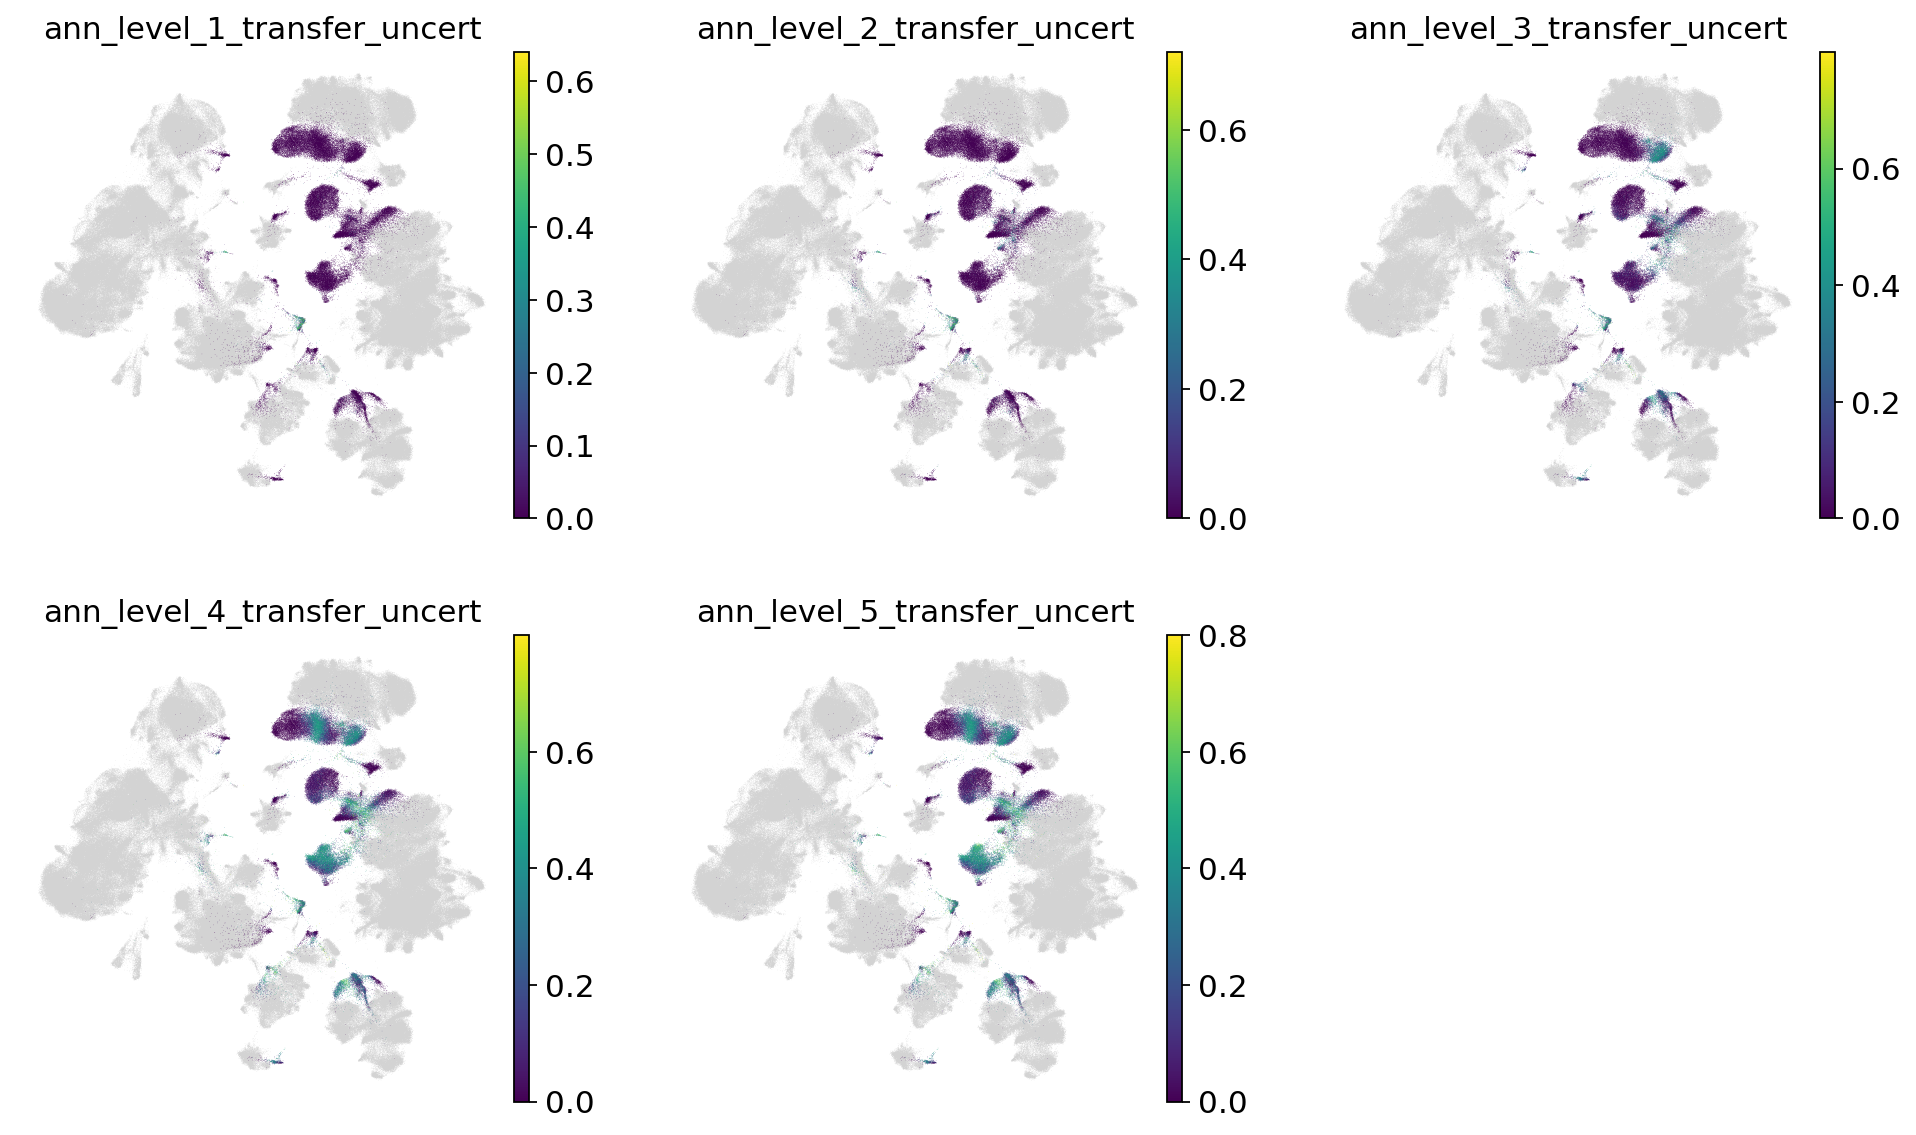

In [54]:
sc.pl.umap(
    combined_emb,
    color=[f"ann_level_{lev}_transfer_uncert" for lev in range(1, 6)],
    ncols=3,
    frameon=False,
)

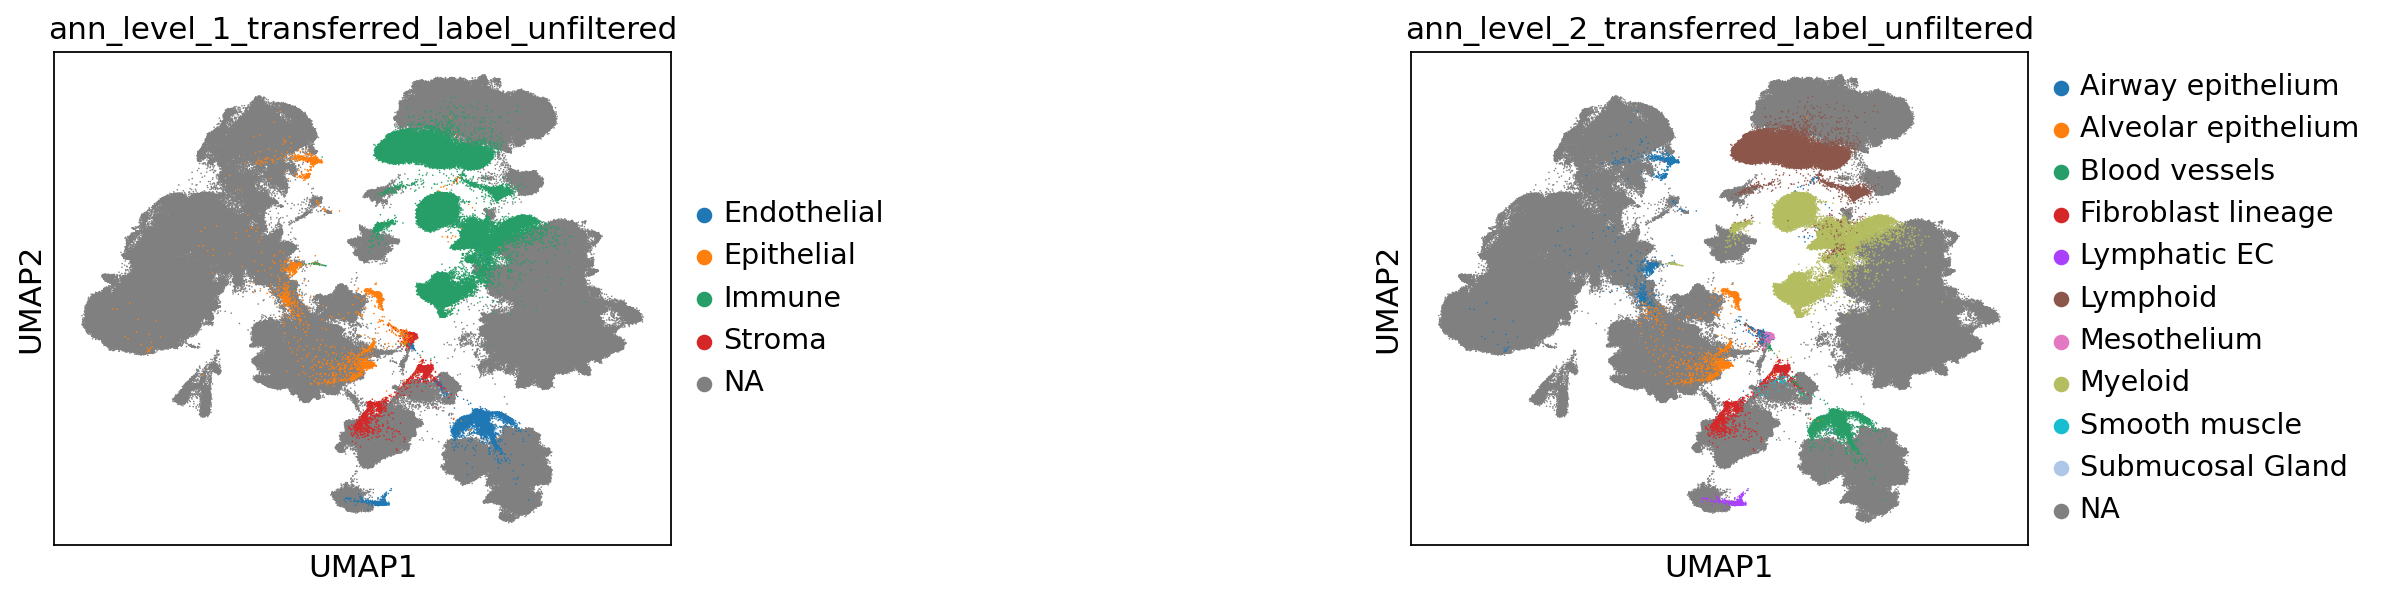

In [55]:
sc.pl.umap(
    combined_emb,
    color=[f"ann_level_{lev}_transferred_label_unfiltered" for lev in range(1, 3)],
    na_color="grey",
    ncols=2,
    size=2,
    wspace=1,
)

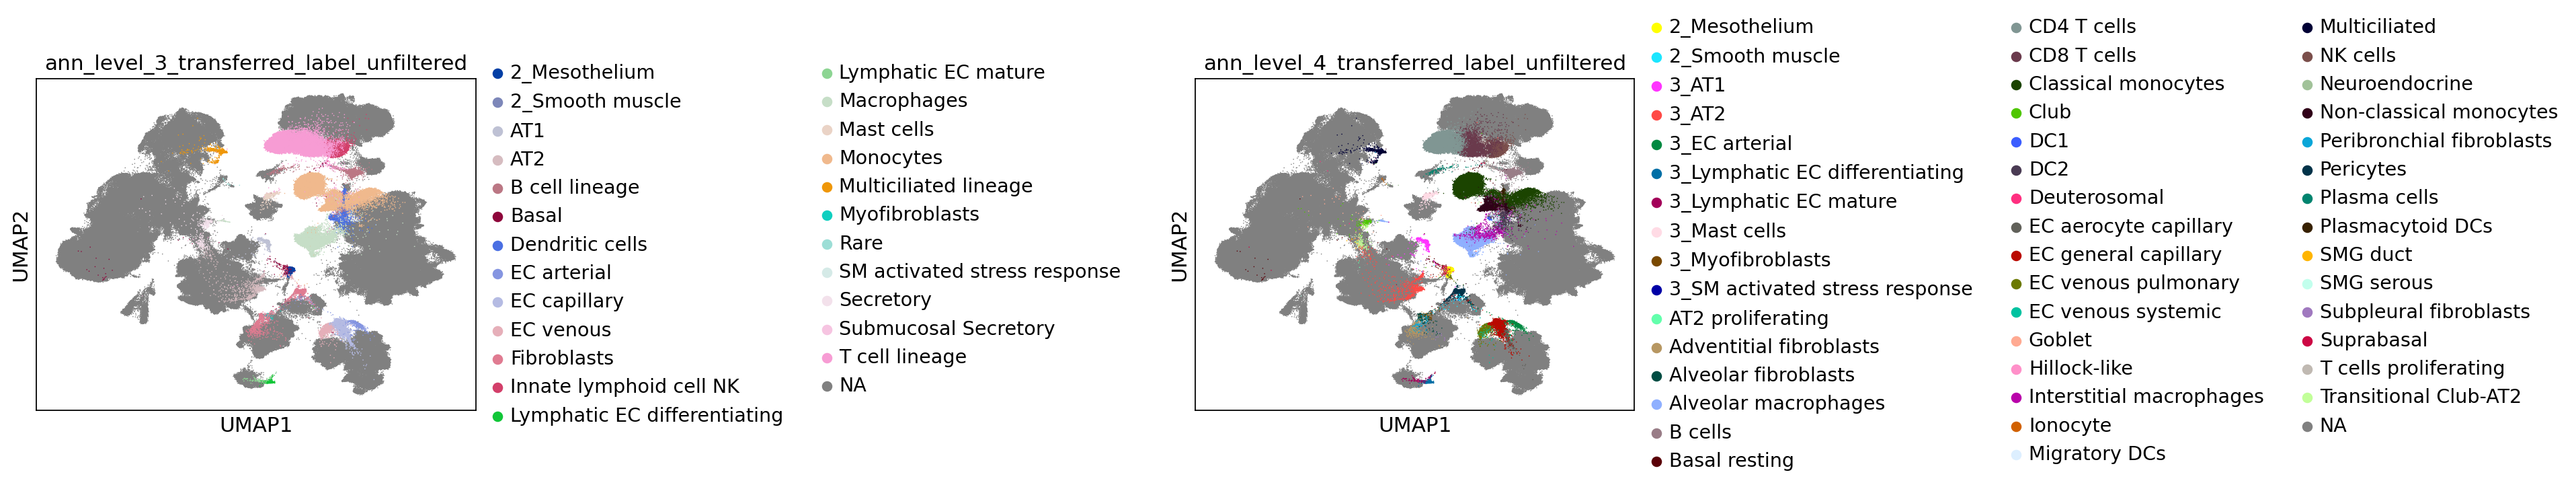

In [56]:
sc.pl.umap(
    combined_emb,
    color=[f"ann_level_{lev}_transferred_label_unfiltered" for lev in range(3, 5)],
    na_color="grey",
    ncols=2,
    size=2,
    wspace=1.4,
)

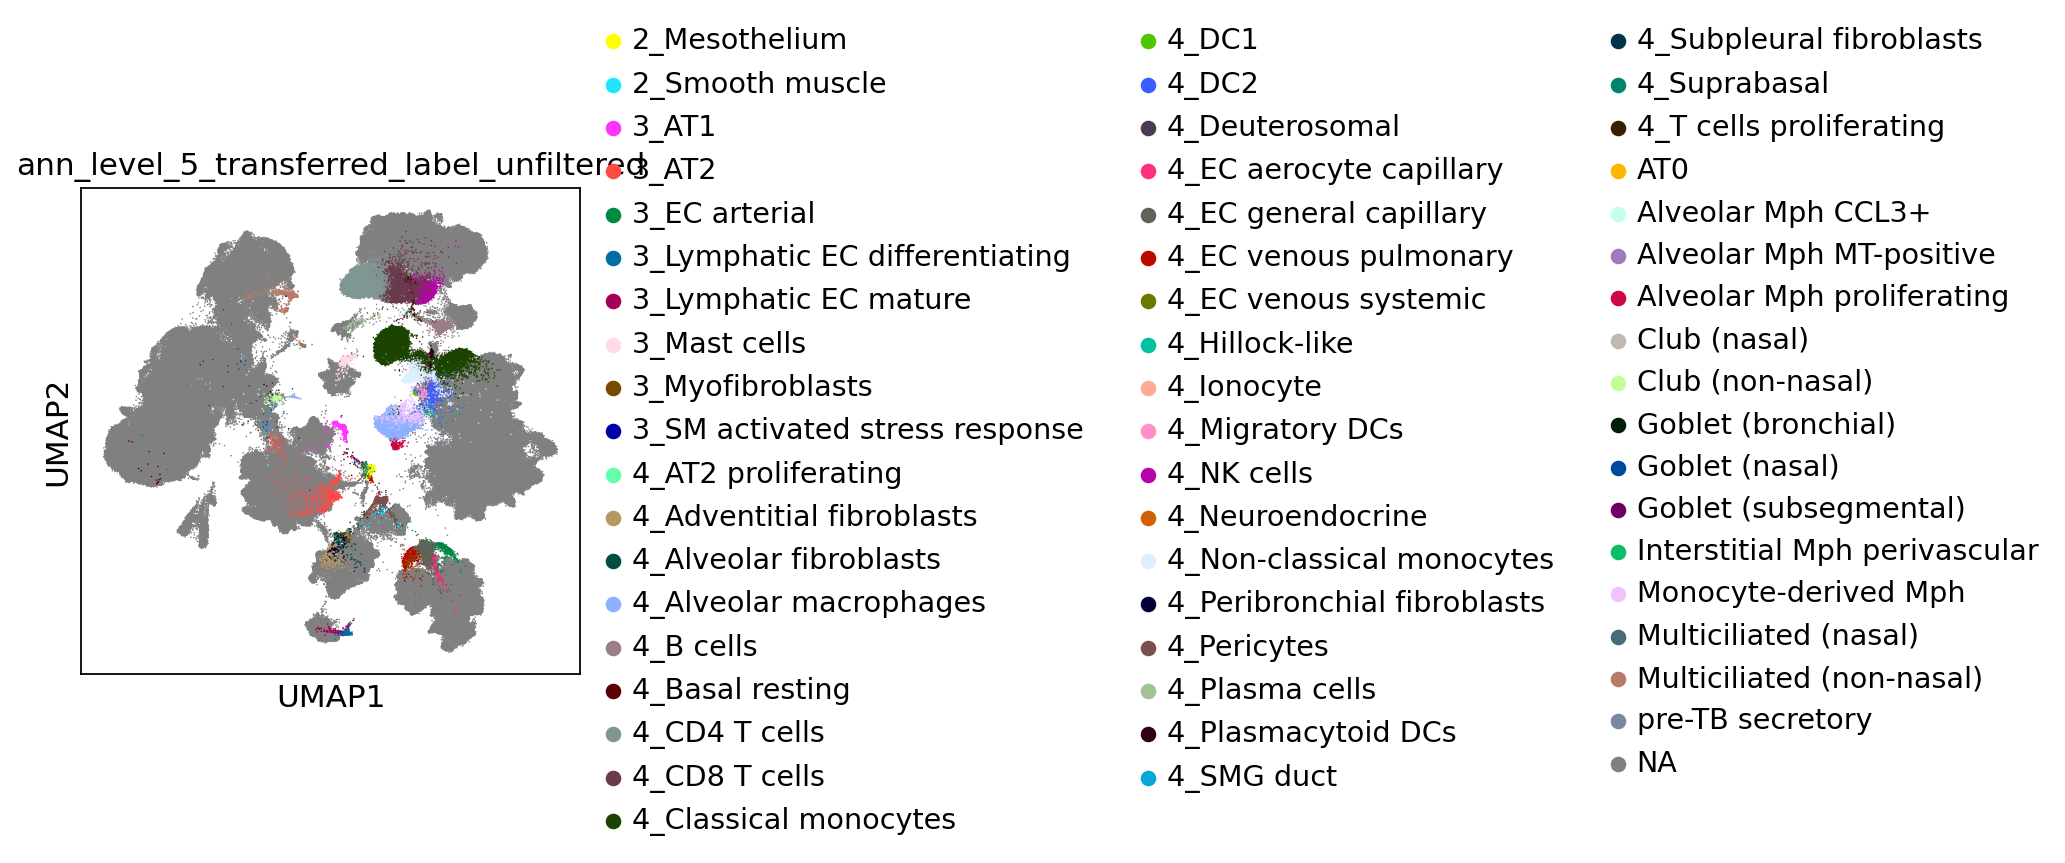

In [57]:
sc.pl.umap(
    combined_emb,
    color=[f"ann_level_5_transferred_label_unfiltered"],
    na_color="grey",
    size=2,
)

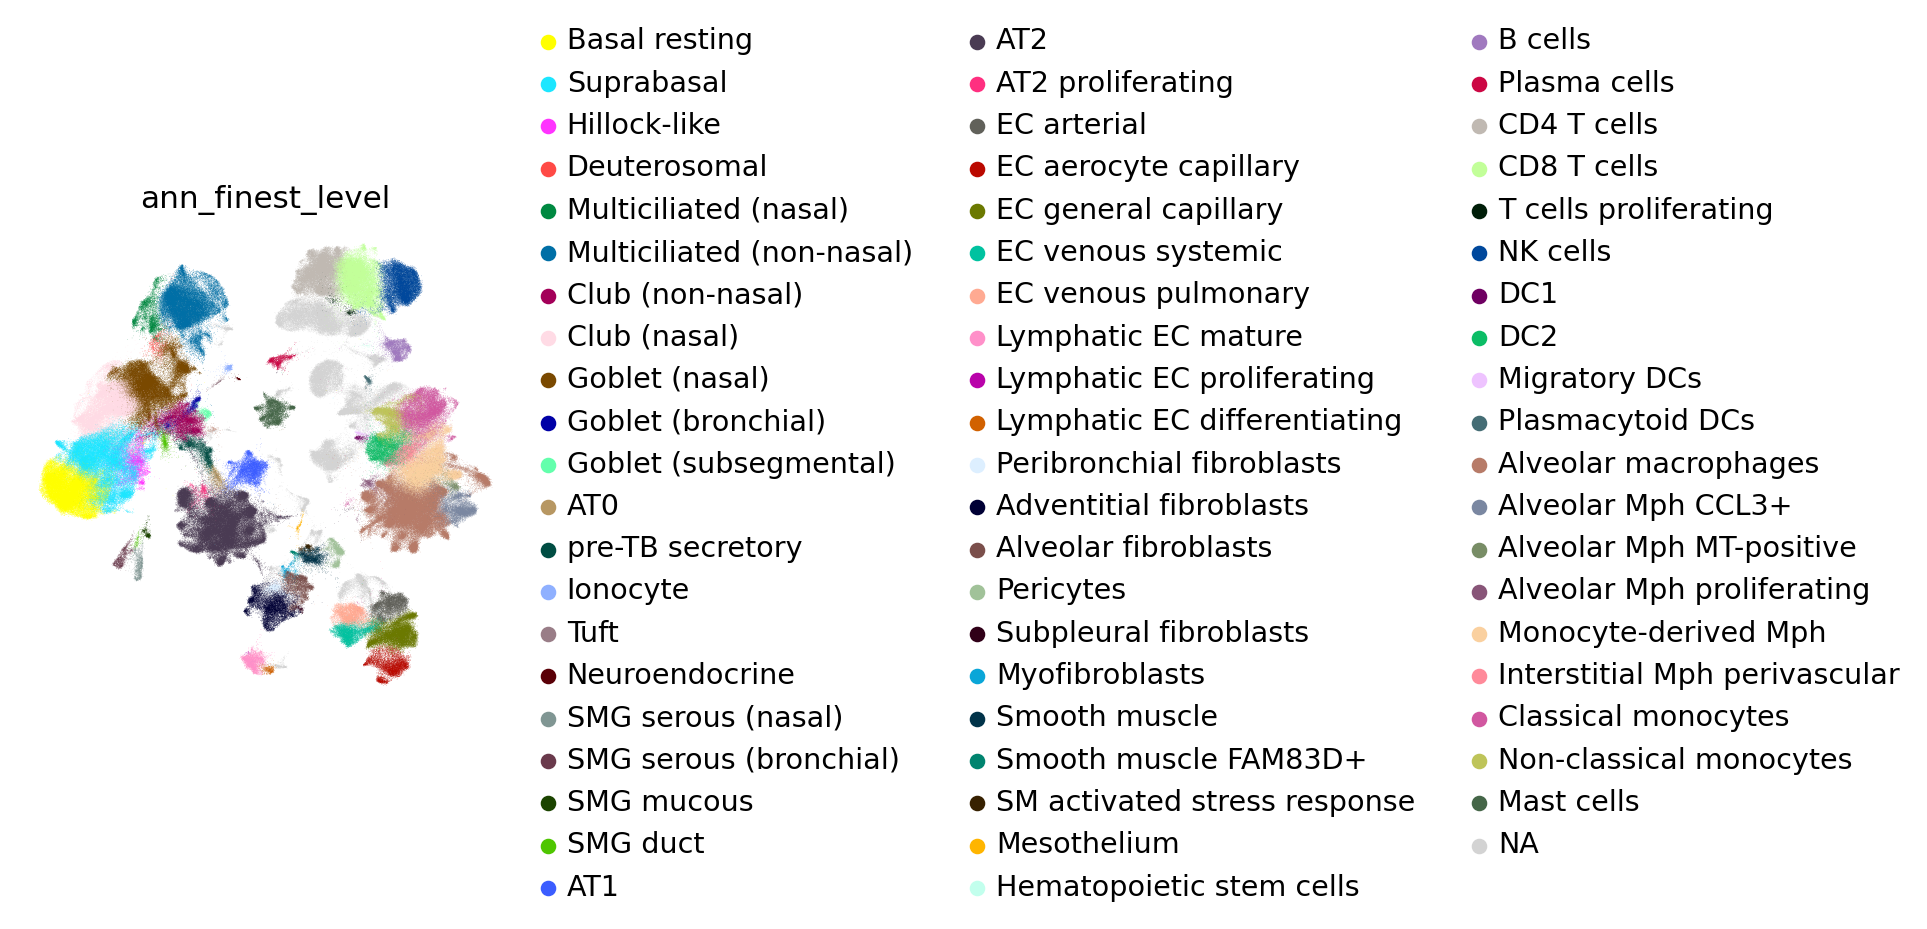

In [58]:
sc.pl.umap(combined_emb, color="ann_finest_level", frameon=False, wspace=0.6)

In [59]:
adata_query_final = (
    adata_query_unprep.copy()
)

In [60]:
adata_query_final.obsm["X_scarches_emb"] = adata_query_latent[
    adata_query_final.obs.index, :
].X 

In [61]:
adata_query_final.var.index = adata_query_final.var.gene_names
adata_query_final.var.index.name = None
adata_query_final.var_names_make_unique()

In [62]:
adata_query_final.layers["counts"] = adata_query_final.X.copy()
sc.pp.normalize_total(adata_query_final, target_sum=1e4)
sc.pp.log1p(adata_query_final)

In [63]:
for col in combined_emb.obs.columns:
    if col.startswith("ann_level") and "transfer" in col:
        adata_query_final.obs[col] = combined_emb.obs.loc[
            adata_query_final.obs.index, col
        ]

In [64]:
sc.pp.neighbors(adata_query_final, use_rep="X_scarches_emb")
sc.tl.umap(adata_query_final)

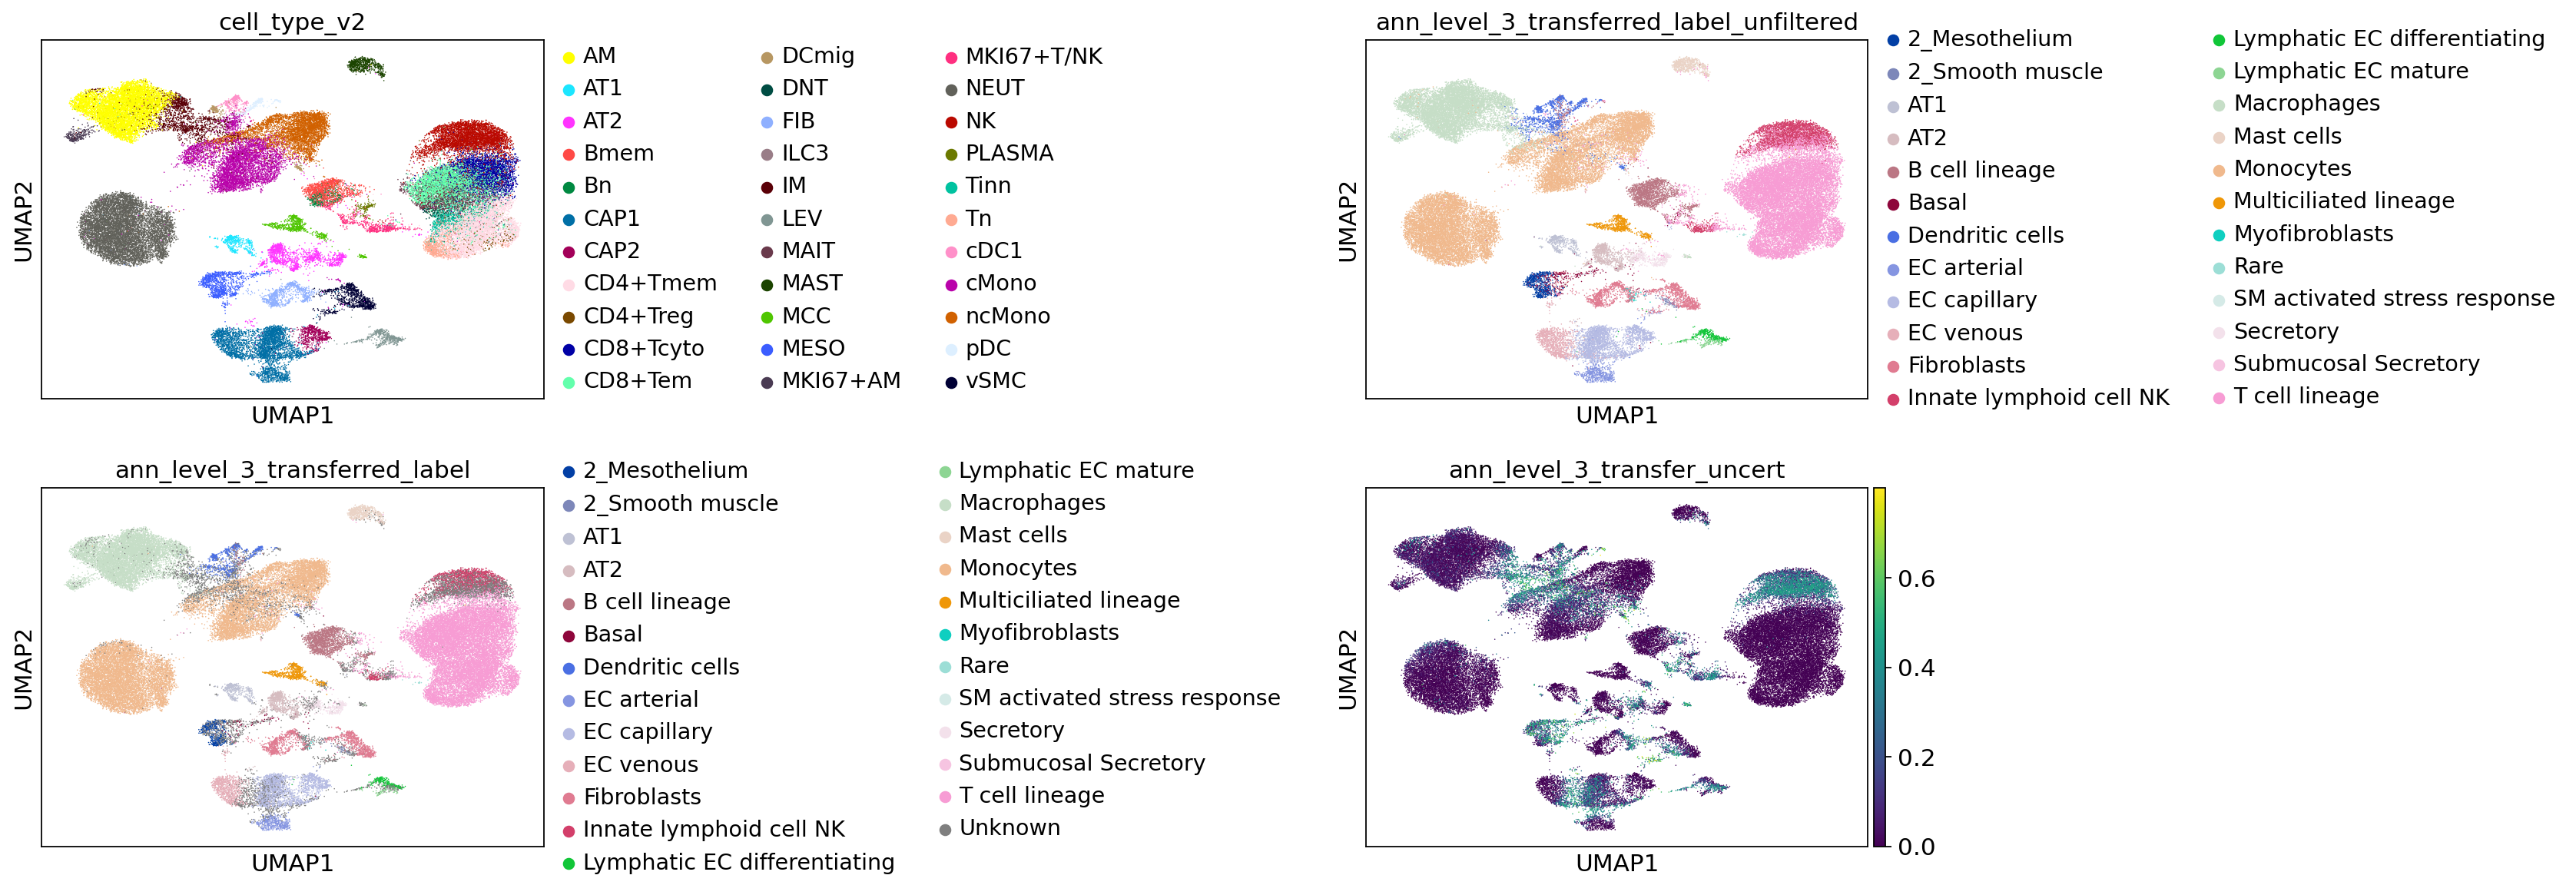

In [65]:
lev = 3
sc.pl.umap(
    adata_query_final,
    color=[
        "cell_type_v2",
        f"ann_level_{lev}_transferred_label_unfiltered",
        f"ann_level_{lev}_transferred_label",
        f"ann_level_{lev}_transfer_uncert",
    ],
    wspace=1.4,
    ncols=2,
)

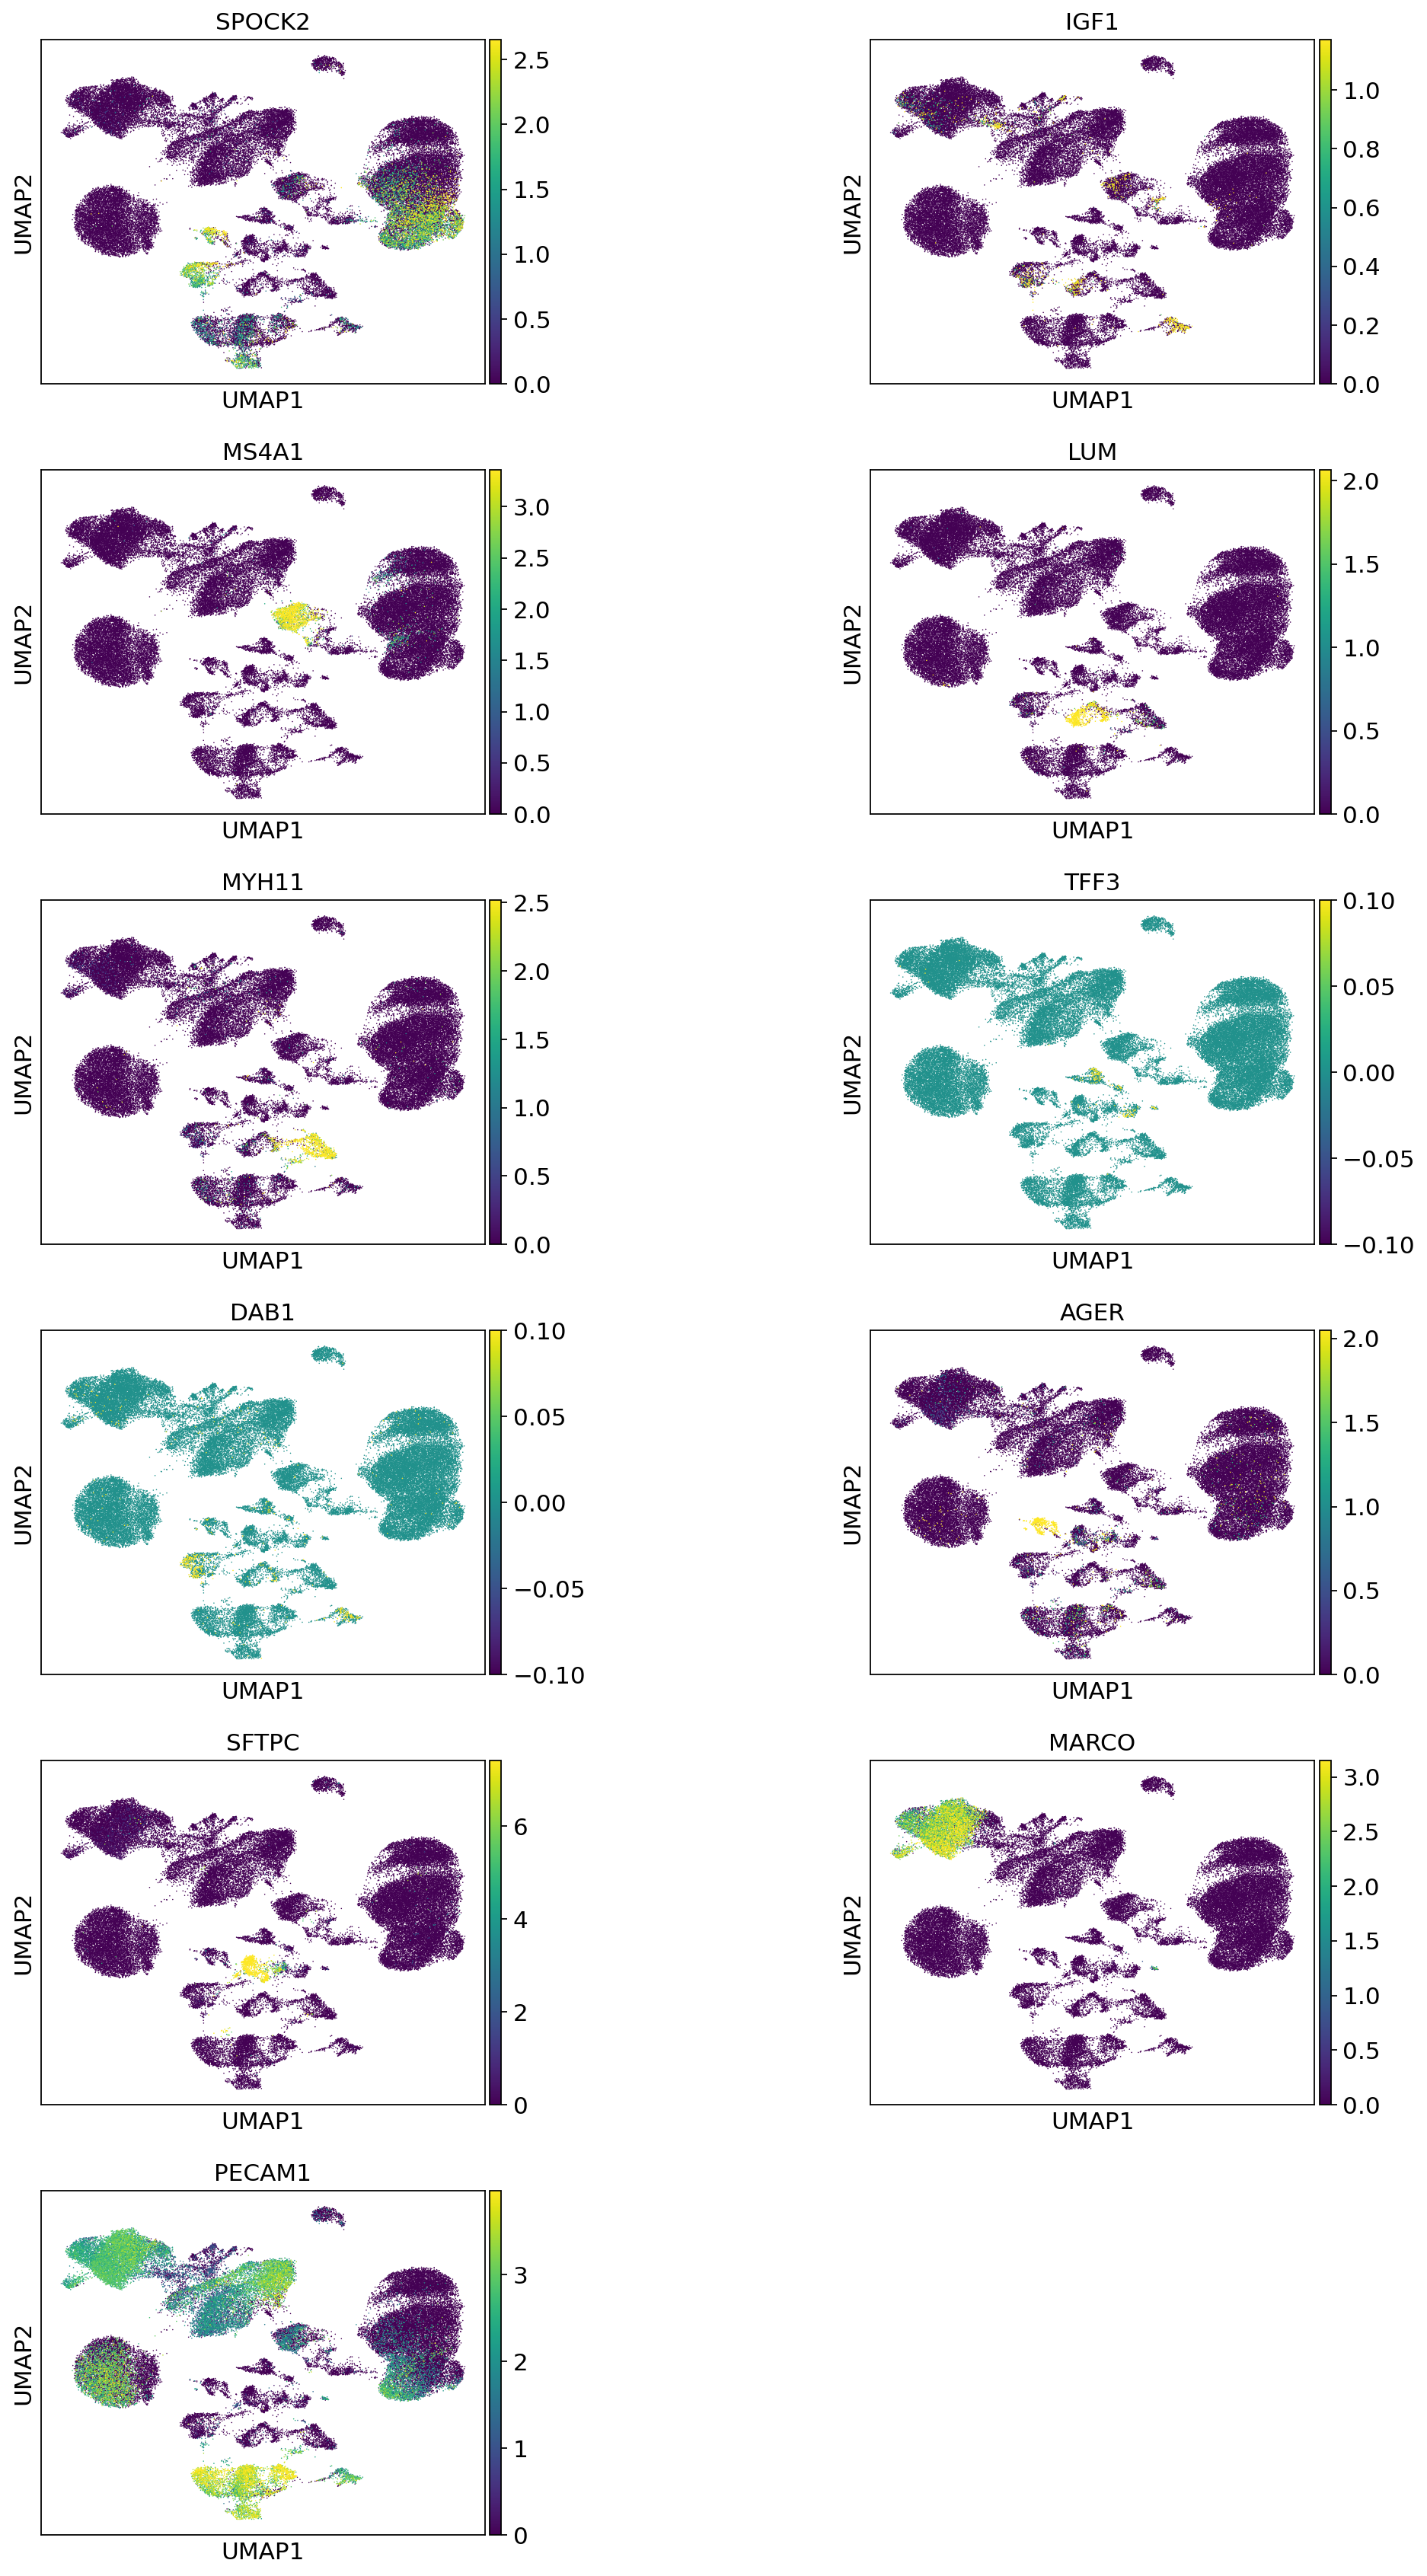

In [66]:
genes = ["SPOCK2", "IGF1", "MS4A1", "LUM", "MYH11", "ECSCR", "TFF3", "DAB1",
         "AGER", "SFTPC", "MARCO", "PECAM1"]
genes = [g for g in genes if g in adata_query_final.var_names]
sc.pl.umap(
    adata_query_final,
    color=genes,
    vmax="p99",
    wspace=0.7,
    ncols=2,
)

In [67]:
adata_query_final.write_h5ad(path_query_final)

In [68]:
export_cols = (["sample", "cell_type_v2"]
               + [f"ann_level_{lev}_transferred_label_unfiltered" for lev in range(1, 6)]
               + [f"ann_level_{lev}_transferred_label" for lev in range(1, 6)]
               + [f"ann_level_{lev}_transfer_uncert" for lev in range(1, 6)])
export = adata_query_final.obs[export_cols].copy()
export.index.name = "cell"
export.to_csv(path_labels_csv)
print(export.shape)

(61612, 17)


In [69]:
def top_label(s):
    vc = s.value_counts(normalize=True)
    return f"{vc.index[0]} ({vc.iloc[0]*100:.0f}%)"

summary = export.groupby("cell_type_v2").agg(
    n_cells=("sample", "size"),
    level3_top=("ann_level_3_transferred_label_unfiltered", top_label),
    level3_median_uncert=("ann_level_3_transfer_uncert", "median"),
    level5_top=("ann_level_5_transferred_label_unfiltered", top_label),
    level5_median_uncert=("ann_level_5_transfer_uncert", "median"),
).round(3)
summary.to_csv(path_summary_csv)
summary

,n_cells,level3_top,level3_median_uncert,level5_top,level5_median_uncert
cell_type_v2,,,,,
AM,7543,Macrophages (100%),0.000,4_Alveolar macrophages (80%),0.26
AT1,471,AT1 (96%),0.000,3_AT1 (96%),0.00
AT2,1460,AT2 (60%),0.000,3_AT2 (61%),0.02
Bmem,1191,B cell lineage (94%),0.000,4_B cells (94%),0.00
Bn,311,B cell lineage (97%),0.000,4_B cells (97%),0.00
CAP1,3661,EC capillary (55%),0.040,4_EC general capillary (56%),0.16
CAP2,600,EC capillary (99%),0.000,4_EC aerocyte capillary (86%),0.14
CD4+Tmem,5051,T cell lineage (100%),0.000,4_CD4 T cells (99%),0.00
CD4+Treg,186,T cell lineage (100%),0.000,4_CD4 T cells (100%),0.00


In [70]:
for ct in ["AT2", "CAP1", "IM", "cDC1", "NK", "CD8+Tem", "FIB", "MESO"]:
    s = (export.loc[export["cell_type_v2"] == ct, "ann_level_5_transferred_label_unfiltered"]
               .value_counts(normalize=True).head(3).round(2))
    print(f"{ct:8s}", dict(s))

AT2      {'3_AT2': np.float64(0.61), 'Club (non-nasal)': np.float64(0.12), 'pre-TB secretory': np.float64(0.11)}
CAP1     {'4_EC general capillary': np.float64(0.56), '4_EC venous pulmonary': np.float64(0.22), '3_EC arterial': np.float64(0.15)}
IM       {'Monocyte-derived Mph': np.float64(0.41), '4_Alveolar macrophages': np.float64(0.23), '4_DC2': np.float64(0.22)}
cDC1     {'4_DC1': np.float64(0.33), '4_DC2': np.float64(0.29), '4_B cells': np.float64(0.21)}
NK       {'4_NK cells': np.float64(0.58), '4_CD8 T cells': np.float64(0.41), '4_CD4 T cells': np.float64(0.01)}
CD8+Tem  {'4_CD8 T cells': np.float64(0.61), '4_CD4 T cells': np.float64(0.39), '4_T cells proliferating': np.float64(0.0)}
FIB      {'4_Adventitial fibroblasts': np.float64(0.4), '4_Alveolar fibroblasts': np.float64(0.29), '4_Peribronchial fibroblasts': np.float64(0.16)}
MESO     {'2_Mesothelium': np.float64(0.65), '4_Suprabasal': np.float64(0.18), '4_EC venous pulmonary': np.float64(0.04)}


In [71]:
missing = pd.read_csv(os.path.join(hlca_dir, "hlca_missing_genes.csv"))
key = ["CD8B", "CD8B2", "CD8A", "CD4", "KLRF1", "NCR1", "FCGR3A", "CD1C", "CLEC10A", "FCER1A",
       "XCR1", "CLEC9A", "SFTPA1", "SFTPA2", "SCGB3A2", "SCGB1A1", "GJA5", "ACKR1"]
print(missing[missing["symbol"].isin(key)].to_string(index=False))

nasal = export["ann_level_5_transferred_label_unfiltered"].str.contains(r"\(nasal\)", regex=True)
print(f"\ncells given a nasal label: {nasal.sum()} ({100*nasal.mean():.2f}%)")

           gene symbol             status
ENSG00000122852 SFTPA1 ortholog_many2many
ENSG00000172116   CD8B  ortholog_one2many
ENSG00000185303 SFTPA2 ortholog_many2many
ENSG00000203747 FCGR3A  ortholog_one2many

cells given a nasal label: 68 (0.11%)


In [72]:
orth = pd.read_csv(path_orthologs)
model_genes = set(ref_model_features)
query_mmul = set(adata_query_unprep.var["gene_ids_mmul"])
for g in ["CD8B", "FCGR3A", "SFTPA1", "SFTPA2"]:
    hid = missing.loc[missing["symbol"] == g, "gene"].iloc[0]
    partners = orth.loc[orth["Human gene stable ID"] == hid, "Gene stable ID"].unique()
    print(f"\n{g} ({hid})")
    for m in partners:
        targets = orth.loc[orth["Gene stable ID"] == m, "Human gene stable ID"]
        in_model = [orth.loc[orth["Human gene stable ID"] == t, "Human gene name"].iloc[0]
                    for t in targets.unique() if t in model_genes]
        print(f"  macaque {m} | in query: {m in query_mmul} | model genes it maps to: {in_model}")


CD8B (ENSG00000172116)
  macaque ENSMMUG00000003532 | in query: False | model genes it maps to: ['CD8B']

FCGR3A (ENSG00000203747)
  macaque ENSMMUG00000016206 | in query: False | model genes it maps to: ['FCGR3A']

SFTPA1 (ENSG00000122852)
  macaque ENSMMUG00000040590 | in query: False | model genes it maps to: ['SFTPA2', 'SFTPA1']
  macaque ENSMMUG00000047229 | in query: False | model genes it maps to: ['SFTPA2', 'SFTPA1']
  macaque ENSMMUG00000057196 | in query: False | model genes it maps to: ['SFTPA2', 'SFTPA1']

SFTPA2 (ENSG00000185303)
  macaque ENSMMUG00000040590 | in query: False | model genes it maps to: ['SFTPA2', 'SFTPA1']
  macaque ENSMMUG00000047229 | in query: False | model genes it maps to: ['SFTPA2', 'SFTPA1']
  macaque ENSMMUG00000057196 | in query: False | model genes it maps to: ['SFTPA2', 'SFTPA1']


In [73]:
all_mmul = set(ad.read_h5ad(path_query_source, backed="r").var["gene_ids"])
for m in ["ENSMMUG00000003532", "ENSMMUG00000016206",
          "ENSMMUG00000040590", "ENSMMUG00000047229", "ENSMMUG00000057196"]:
    print(m, m in all_mmul)

ENSMMUG00000003532 True
ENSMMUG00000016206 True
ENSMMUG00000040590 True
ENSMMUG00000047229 True
ENSMMUG00000057196 True


In [74]:
col5 = "ann_level_5_transferred_label_unfiltered"
dc2 = export[export[col5] == "4_DC2"]
print(f"cells labeled DC2: {len(dc2)}")
print(dc2["cell_type_v2"].value_counts().to_string())
print(dc2.groupby("cell_type_v2")["ann_level_5_transfer_uncert"].median().round(2).to_string())

cells labeled DC2: 792
cell_type_v2
IM            374
cMono         250
cDC1          103
DCmig          30
pDC            26
ncMono          4
PLASMA          1
Bmem            1
MESO            1
MKI67+AM        1
MKI67+T/NK      1
AM              0
AT1             0
CAP1            0
CAP2            0
AT2             0
Bn              0
LEV             0
ILC3            0
FIB             0
DNT             0
CD8+Tcyto       0
CD8+Tem         0
CD4+Tmem        0
CD4+Treg        0
NK              0
NEUT            0
MAST            0
MCC             0
MAIT            0
Tinn            0
Tn              0
vSMC            0
cell_type_v2
AM             NaN
AT1            NaN
AT2            NaN
Bmem          0.22
Bn             NaN
CAP1           NaN
CAP2           NaN
CD4+Tmem       NaN
CD4+Treg       NaN
CD8+Tcyto      NaN
CD8+Tem        NaN
DCmig         0.45
DNT            NaN
FIB            NaN
ILC3           NaN
IM            0.36
LEV            NaN
MAIT           NaN
MAST           